# Rotating Disk Electrode (RDE) Hydrodynamics: Levich & Koutecký–Levich Analysis

This tutorial demonstrates multi-rotation-rate hydrodynamic simulation using [`RotatingDiskElectrode`](../api/techniques.md), `simulate_rde_sweep()`, `plot_sweep()`, `analyze_levich()`, and `analyze_koutecky_levich()`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from softpotato.constants import FARADAY
from softpotato.geometry import PlanarGeometry
from softpotato.reactions import (
    ButlerVolmer,
    CustomMechanism,
    NernstianEquilibrium,
    Species,
)
from softpotato.solver import DirichletBC, NeumannBC
from softpotato.techniques import (
    RotatingDiskElectrode,
    TechniqueResult,
    analyze_koutecky_levich,
    analyze_levich,
    plot_koutecky_levich,
    plot_levich,
    plot_sweep,
    simulate,
    simulate_rde_sweep,
)

D = 1e-9  # m^2/s
c_bulk = 1.0  # mol/m^3 (1 mM)
area = 1e-4  # m^2 (1 cm^2)
rpms = [400, 900, 1600, 2500]

## 1. Reversible RDE Sweep & Levich Analysis

We run a multi-rotation-rate RDE linear sweep under the Nernst stagnant diffusion layer model (`model="nernst_layer"`), overlay the hydrodynamic voltammograms with `plot_sweep()`, and extract the diffusivity $D$ via `analyze_levich()` and `plot_levich()`.

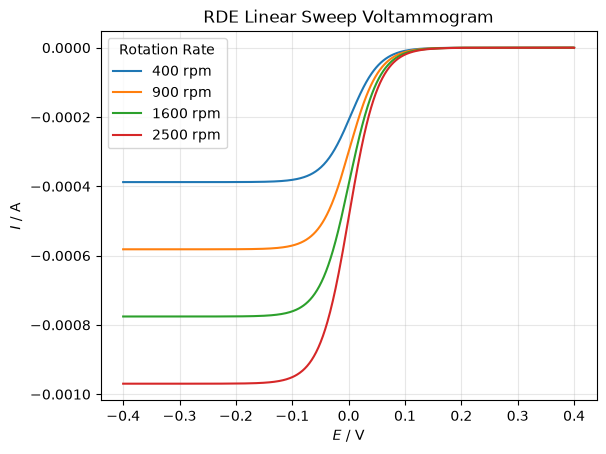

Estimated D (Levich) = 1.003e-09 m^2/s (true: 1.000e-09 m^2/s)


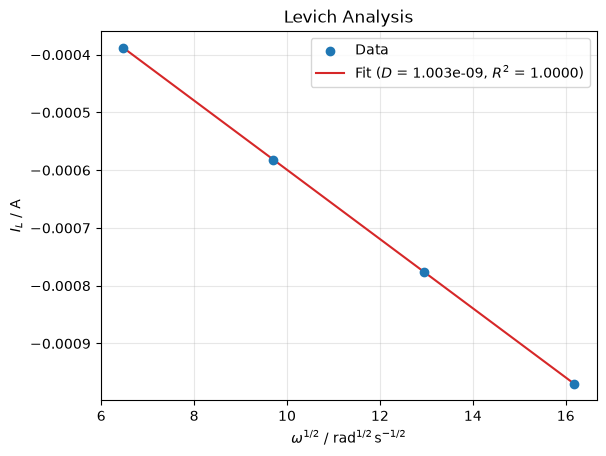

In [2]:
rde_rev = simulate_rde_sweep(
    rpms=rpms,
    E_start=0.4,
    E_end=-0.4,
    scan_rate=0.02,
    D=D,
    c_bulk=c_bulk,
    area=area,
    n_electrons=1,
    kinetics=NernstianEquilibrium(E0=0.0, n=1),
    model="nernst_layer",
    solver_kwargs={"rtol": 1e-8, "atol": 1e-10},
)

fig_sweep, ax_sweep = plot_sweep(rde_rev, legend_title="Rotation Rate")
plt.show()

levich_fit = analyze_levich(rde_rev, n=1, area=area, c_bulk=c_bulk)
print(f"Estimated D (Levich) = {levich_fit.d:.3e} m^2/s (true: {D:.3e} m^2/s)")

fig_lev, ax_lev = plot_levich(rde_rev, levich_fit)
plt.show()

## 2. Mixed Kinetic–Diffusion Control & Koutecký–Levich Analysis

With finite Butler–Volmer kinetics ($k^0 = 5 \times 10^{-5}\,\text{m/s}$), the current at intermediate overpotentials reflects both mass transport and interfacial kinetics. `analyze_koutecky_levich()` separates the kinetic current $I_K$ ($k^0$) from the Levich slope $B$ ($D$).

Kinetic current |I_k| = 8.558e-03 A, k = 8.870e-04 m/s, D = 1.007e-09 m^2/s


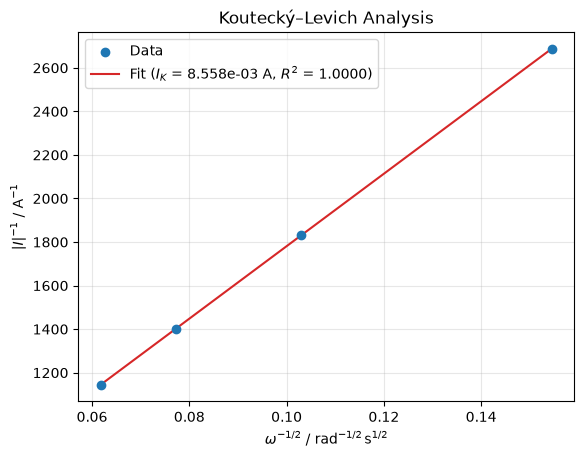

In [3]:
bv_rde = ButlerVolmer(k0=5e-5, alpha=0.5, E0=0.0, n=1)
ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, n_electrons=1)
red = Species("Red", diffusivity=D, bulk_concentration=0.0, n_electrons=-1)
geom = PlanarGeometry(area=area)

rde_kin_results = []
for rpm in rpms:
    rde = RotatingDiskElectrode(
        E_start=0.4, E_end=-0.4, scan_rate=0.02, rpm=rpm, model="nernst_layer"
    )
    grid = rde.build_grid(D=D, n_points=80, kind="geometric", gamma=1.06)
    inv_h0 = 2.0 / float(grid.nodes[1] - grid.nodes[0])

    def rates(c, x, t, _rde=rde, _inv=inv_h0):
        kf, kb = bv_rde.rate_constants(float(_rde.potential(t)))
        j_bv = float(kf) * c["Ox"][0] - float(kb) * c["Red"][0]
        r_ox = np.zeros_like(c["Ox"])
        r_red = np.zeros_like(c["Red"])
        r_ox[0] = -_inv * j_bv
        r_red[0] = _inv * j_bv
        return {"Ox": r_ox, "Red": r_red}

    mech = CustomMechanism(species=[ox, red], rates=rates, name="RDE_BV")
    res = simulate(
        rde,
        mech,
        geometry=geom,
        grid=grid,
        bc_overrides={
            "Ox": (NeumannBC(0.0), DirichletBC(c_bulk)),
            "Red": (NeumannBC(0.0), DirichletBC(0.0)),
        },
        solver_kwargs={"method": "Radau", "rtol": 1e-6, "atol": 1e-9},
    )
    kf_arr, kb_arr = bv_rde.rate_constants(res.potential)
    i_bv = (
        -FARADAY
        * area
        * (np.asarray(kf_arr) * res["Ox"][:, 0] - np.asarray(kb_arr) * res["Red"][:, 0])
    )
    rde_kin_results.append(
        TechniqueResult(
            technique=rde,
            solver_result=res.solver_result,
            time=res.time,
            potential=res.potential,
            current=i_bv,
        )
    )

kl_fit = analyze_koutecky_levich(
    rde_kin_results, potential=-0.15, n=1, area=area, c_bulk=c_bulk
)
print(
    f"Kinetic current |I_k| = {abs(kl_fit.i_k):.3e} A, "
    f"k = {kl_fit.k_rate:.3e} m/s, D = {kl_fit.d:.3e} m^2/s"
)

fig_kl, ax_kl = plot_koutecky_levich(rde_kin_results, kl_fit, potential=-0.15)
plt.show()